# Обучаемые функции

## 0. Условие

1. Выбрать табличный набор данных для задачи классификации:
    - В котором есть категориальные (не менее двух), и числовые признаки.
    - Необходимо предобработать его: заполнить пропуски, нормализовать и т.д.. Разбить на тренировочную и тестовую часть.
    - Даже если набор данных будет для бинарной классификации, реализация не должна специализироваться под это.
2. Реализовать стандартное обучаемое преобразование: умножение на матрицу, добавление вектора и применение функции активации.
    - Преобразование должно пересчитывать градиент для входа и параметров.
    - Должны поддерживаться не менее трёх функций активации (кроме `Sigmoid`, `Tanh`, `ReLU` и `Softmax`).
3. Реализовать модификацию матричного обучаемого преобразования, в котором скалярное произведение заменено на RBF ядро из SVM.
    - То есть, каждая координата вектора выхода получается как расстояние вектора входа с соответствующим вектором из матрицы параметров, а затем к нему применяется гауссова функция.
    - Для данного преобразования также необходимо реализовать пересчёт градиента.
4. Реализовать обёртку над преобразованиями, которая будет добавлять остаточную связь.
5. Реализовать функцию ошибки `SoftArgMaxCrossEntropy`, которая будет стабильно применять к вектору композицию `SoftArgMax` преобразования и логарифма, для вычисления перекрёстной энтропии с целевым вектором. Данная функция также должна вычислять градиент.
6. Реализовать любую модификацию адаптивного градиентного спуска.
7. Обучить несколько моделей с разным числом стандартных матричных преобразований. 
    - Для каждой модели подобрать хорошие гиперпараметры.
    - Проверить влияние остаточных связей, добавления слоёв батч-нормализации и дропаута.
    - На одном графике - соответствующие кривые обучения.
    - Замерить качество классификации (точность или F-меру) на тестовой части, построить зависимость от числа параметров и преобразований.
8. Повторить предыдущий шаг для модифицированного матричного преобразования.
9. Построить модель из комбинации обычных и модифицированных матричных преобразований. Повторить седьмой шаг для них.


In [1]:
# Python's own stuff
import sys
import math
import dataclasses
import time
import warnings
import itertools as itt
import operator as op
from pathlib import Path
from dataclasses import dataclass, field
from dataclasses import asdict as dc_asdict
from abc import ABC, abstractmethod
from contextlib import contextmanager

# Numpy/Scipy/other
import numpy as np
import scipy.special as sp_spec
import scipy.stats as sp_stats
import pickle
import sklearn as skl
from sklearn.model_selection import train_test_split

# Visualisation
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from ipywidgets import interactive, IntSlider, FloatSlider
from IPython.display import display, Markdown

# Type checking
from typing import TYPE_CHECKING
from typing import override

if TYPE_CHECKING:
    from typing import Callable, Optional, Sequence
    from collections.abc import Iterable
    from numpy.typing import NDArray

# Config
np.set_printoptions(precision=4, suppress=True)
plt.rcParams["axes.grid"] = True
plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")

# Versions
print(f"Python={sys.version_info}")
print(f"numpy={np.__version__}  sklearn={skl.__version__} matplotlib={mpl.__version__}  pandas={pd.__version__}")


Python=sys.version_info(major=3, minor=14, micro=3, releaselevel='final', serial=0)
numpy=2.5.3  sklearn=1.9.1 matplotlib=3.11.2  pandas=3.0.6


## 1. Датасет

### Выбор


In [2]:
def fetch_ucirepo_cached(dataset_id: int, cache_dir: str | Path = "../../data_cache"):
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)

    cache_path = cache_dir / f"uci_dataset_{dataset_id}.pkl"

    if cache_path.is_file():
        with cache_path.open("rb") as f:
            return pickle.load(f)
    else:
        from ucimlrepo import fetch_ucirepo
        dataset = fetch_ucirepo(id=dataset_id)

        with cache_path.open("wb") as f:
            pickle.dump(dataset, f)

        return dataset

# fetch dataset 
DATASET_RAW = fetch_ucirepo_cached(30)

# metadata 
print("Название:", DATASET_RAW.metadata["name"])
print("Описание:", DATASET_RAW.metadata["additional_info"]["summary"], sep="\n")
print("Задачи:", DATASET_RAW.metadata["tasks"])
print("Переменные:", DATASET_RAW.metadata["additional_info"]["variable_info"], sep="\n")

# variable information 
print(DATASET_RAW.variables) 


Название: Contraceptive Method Choice
Описание:
This dataset is a subset of the 1987 National Indonesia Contraceptive Prevalence Survey. The samples are married women who were either not pregnant or do not know if they were at the time of interview. The problem is to predict the current contraceptive method choice (no use, long-term methods, or short-term methods) of a woman based on her demographic and socio-economic characteristics.
Задачи: ['Classification']
Переменные:
   1. Wife's age                     (numerical)
   2. Wife's education               (categorical)      1=low, 2, 3, 4=high
   3. Husband's education            (categorical)      1=low, 2, 3, 4=high
   4. Number of children ever born   (numerical)
   5. Wife's religion                (binary)           0=Non-Islam, 1=Islam
   6. Wife's now working?            (binary)           0=Yes, 1=No
   7. Husband's occupation           (categorical)      1, 2, 3, 4
   8. Standard-of-living index       (categorical)      1=lo

Итого - подходит:
- 2 численных признака
- 7 категориальных (только 3 бинарных)
- 3 категории ответа
- пропусков нет

### Предобработка

Теперь конвертируем в пригодный для модели вид и подготовим генерацию train/test с нормализацией.


In [3]:
def encode_features(dataset):
    from sklearn.preprocessing import OneHotEncoder, LabelEncoder

    X_raw = dataset.data.features
    y_raw = dataset.data.targets.iloc[:, 0]

    vars_df = dataset.variables.copy()

    if "name" not in vars_df.columns:
        vars_df = vars_df.reset_index()

    fm = vars_df.set_index("name")
    fm = fm[fm["role"] == "Feature"]

    numeric_cols = fm.loc[
        fm["type"].isin(["Integer", "Continuous"]), :
    ].index.tolist()

    categorical_cols = fm.loc[
        fm["type"].isin(["Categorical", "Binary"]), :
    ].index.tolist()

    target_encoder = LabelEncoder()
    y = target_encoder.fit_transform(y_raw)

    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    X_cat = ohe.fit_transform(X_raw[categorical_cols])
    X_num = X_raw[numeric_cols].to_numpy(dtype=float)

    X = np.hstack([X_num, X_cat])
    feature_names = numeric_cols + list(ohe.get_feature_names_out(categorical_cols))

    meta = {
        "numeric_cols": numeric_cols,
        "categorical_cols": categorical_cols,
        "numeric_idx": list(range(len(numeric_cols))),
        "feature_names": feature_names,
        "encoder": ohe,
        "target_encoder": target_encoder,
    }
    return X, y, meta

DATASET_X, DATASET_y, DATASET_meta = encode_features(DATASET_RAW)
print(DATASET_X, DATASET_y, DATASET_meta, sep="\n")

DATASET_WIDTH = DATASET_X.shape[1]
DATASET_LENGTH = DATASET_y.shape[0]
DATASET_NUM_CLASSES = len(np.unique(DATASET_y))
print(DATASET_WIDTH, DATASET_LENGTH, DATASET_NUM_CLASSES)


[[24.  3.  0. ...  0.  1.  0.]
 [45. 10.  1. ...  1.  1.  0.]
 [43.  7.  0. ...  1.  1.  0.]
 ...
 [39.  8.  0. ...  1.  1.  0.]
 [33.  4.  0. ...  0.  1.  0.]
 [17.  1.  0. ...  1.  1.  0.]]
[0 0 0 ... 2 2 2]
{'numeric_cols': ['wife_age', 'num_children'], 'categorical_cols': ['wife_edu', 'husband_edu', 'wife_religion', 'wife_working', 'husband_occupation', 'standard_of_living_index', 'media_exposure'], 'numeric_idx': [0, 1], 'feature_names': ['wife_age', 'num_children', 'wife_edu_1', 'wife_edu_2', 'wife_edu_3', 'wife_edu_4', 'husband_edu_1', 'husband_edu_2', 'husband_edu_3', 'husband_edu_4', 'wife_religion_0', 'wife_religion_1', 'wife_working_0', 'wife_working_1', 'husband_occupation_1', 'husband_occupation_2', 'husband_occupation_3', 'husband_occupation_4', 'standard_of_living_index_1', 'standard_of_living_index_2', 'standard_of_living_index_3', 'standard_of_living_index_4', 'media_exposure_0', 'media_exposure_1'], 'encoder': OneHotEncoder(handle_unknown='ignore', sparse_output=False

In [4]:
def normalize_train_test(X_train, X_test, numeric_idx=None, *, scaler=None):
    if scaler is None:
        from sklearn.preprocessing import StandardScaler
        scaler = StandardScaler()

    X_train = np.asarray(X_train, dtype=float)
    X_test = np.asarray(X_test, dtype=float)

    if numeric_idx is None:
        return scaler.fit_transform(X_train), scaler.transform(X_test), scaler

    numeric_idx = np.asarray(numeric_idx, dtype=int)
    X_train_out = X_train.copy()
    X_test_out = X_test.copy()

    X_train_out[:, numeric_idx] = scaler.fit_transform(X_train[:, numeric_idx])
    X_test_out[:, numeric_idx] = scaler.transform(X_test[:, numeric_idx])

    return X_train_out, X_test_out, scaler

def make_train_test(test_size: float = 0.2, random_state:int = 30):
    from sklearn.model_selection import train_test_split

    X_train, X_test, y_train, y_test = train_test_split(
        DATASET_X, DATASET_y, test_size=test_size, stratify=DATASET_y, random_state=random_state
    )
    
    X_train_n, X_test_n, scaler = normalize_train_test(
        X_train, X_test, numeric_idx=DATASET_meta["numeric_idx"]
    )

    return (X_train_n, y_train), (X_test_n, y_test), scaler

print(*make_train_test(), sep="\n")


(array([[-0.316 , -0.5496,  0.    , ...,  0.    ,  1.    ,  0.    ],
       [-0.4382, -0.5496,  0.    , ...,  0.    ,  1.    ,  0.    ],
       [ 0.1727, -0.5496,  0.    , ...,  0.    ,  1.    ,  0.    ],
       ...,
       [ 2.0053,  1.6027,  0.    , ...,  1.    ,  1.    ,  0.    ],
       [ 0.6614,  0.7418,  0.    , ...,  0.    ,  1.    ,  0.    ],
       [-1.4156, -0.98  ,  0.    , ...,  0.    ,  1.    ,  0.    ]],
      shape=(1178, 24)), array([2, 1, 1, ..., 0, 0, 1], shape=(1178,)))
(array([[ 0.417 ,  0.7418,  0.    , ...,  1.    ,  1.    ,  0.    ],
       [-1.1712, -0.98  ,  0.    , ...,  0.    ,  1.    ,  0.    ],
       [-1.2934, -0.98  ,  0.    , ...,  0.    ,  1.    ,  0.    ],
       ...,
       [ 0.7836, -0.1191,  0.    , ...,  1.    ,  1.    ,  0.    ],
       [ 1.0279,  3.3245,  0.    , ...,  0.    ,  1.    ,  0.    ],
       [-1.2934, -0.98  ,  0.    , ...,  0.    ,  1.    ,  0.    ]],
      shape=(295, 24)), array([2, 0, 2, 0, 1, 1, 1, 2, 0, 2, 0, 2, 2, 0, 2, 2, 2, 0,

## 2. Стандартное обуч. преобразование

### Функции активации


In [5]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def softplus(x):
    return np.logaddexp(0.0, x)


def activation_swish(x):
    return x * sigmoid(x)


def activation_grad_swish(x):
    s = sigmoid(x)
    return s + x * s * (1.0 - s)


def activation_make_plu(alpha=1.0, beta=1.0):
    ae, be = np.exp(alpha), np.exp(beta)
    scale = be / (1.0 + abs(be))

    def f(x):
        return x + scale * np.sin(ae * x)

    def df(x):
        return 1.0 + scale * ae * np.cos(ae * x)

    return f, df


def activation_make_srelu(tl=-1.0, al=0.1, tr=1.0, ar=0.1):
    def f(x):
        return np.where(x <= tl, tl + al * (x - tl), np.where(x >= tr, tr + ar * (x - tr), x))

    def df(x):
        return np.where(x <= tl, al, np.where(x >= tr, ar, 1.0))

    return f, df


In [6]:
ACTIVATIONS = {
    "swish": (activation_swish, activation_grad_swish),
    "plu": activation_make_plu(alpha=1.8, beta=-1.8),                # alpha - частота sin, beta - сила sin
    "srelu": activation_make_srelu(tl=-1.0, al=0.1, tr=0.5, ar=0.2), # tl, tr - левая и правая границы; al, ar - множители за соотв. границами
}


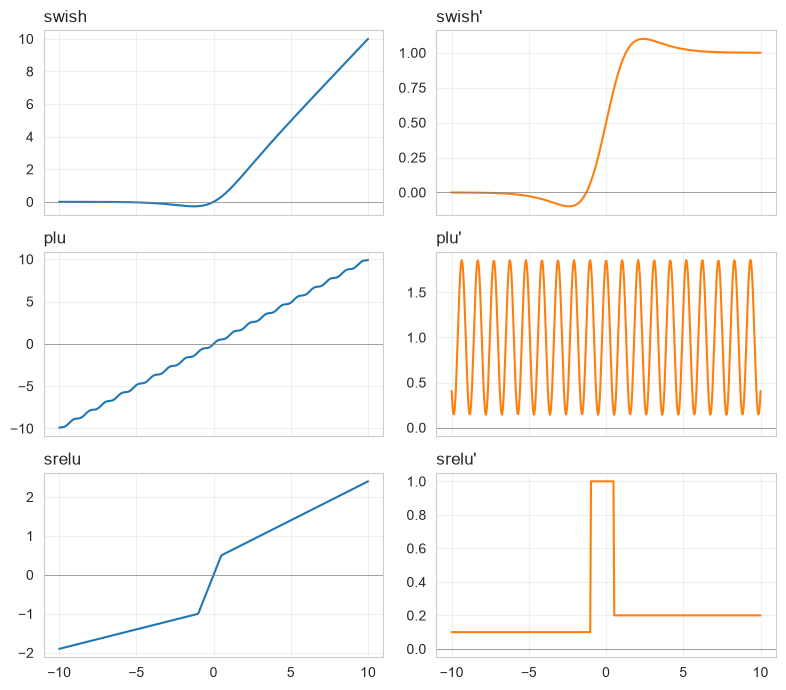

In [7]:
def demo_activations():
    x = np.linspace(-10, 10, 400)

    fig, ax = plt.subplots(len(ACTIVATIONS), 2, figsize=(8, 7), sharex=True)

    for row, (name, (f, df)) in zip(ax, ACTIVATIONS.items()):
        row[0].plot(x, f(x),  color="C0");  row[0].set_title(name, loc="left")
        row[1].plot(x, df(x), color="C1");  row[1].set_title(f"{name}'", loc="left")

        for a in row:
            a.axhline(0, color="gray", lw=0.5)
            a.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

demo_activations()


### Преобразование

Плюс тест через конечные разности.


In [8]:
class BaseTransform(ABC):
    # forward(x) -> y
    # backward(grad_output) -> (grad_x, grad_W, grad_b).

    def __init__(self, in_features, out_features):
        self.in_features = in_features
        self.out_features = out_features

    @abstractmethod
    def forward(self, x): ...

    @abstractmethod
    def backward(self, grad_output): ...

    @abstractmethod
    def parameters(self, prefix=""): ...

    @abstractmethod
    def gradients(self, prefix=""): ...

    def __call__(self, x):
        return self.forward(x)


In [9]:
class BaseTrainableTransform(BaseTransform):
    def __init__(self, in_features, out_features, activation="swish"):
        assert activation in ACTIVATIONS

        super().__init__(in_features, out_features)

        self.activation = activation
        self._f, self._df = ACTIVATIONS[activation]

        self._cache: dict | None = None

    @override
    def parameters(self, prefix=""):
        return {prefix + "W": self.W, prefix + "b": self.b}

    @override
    def gradients(self, prefix=""):
        return {prefix + "W": self._cache["grad_W"], prefix + "b": self._cache["grad_b"]}

class TrainableTransform(BaseTrainableTransform):
    def __init__(self, in_features, out_features, activation="swish", rng=None):
        super().__init__(in_features, out_features, activation)

        rng = rng if rng is not None else np.random.default_rng(30)
        scale = np.sqrt(2.0 / (in_features + out_features))

        self.W = rng.normal(0.0, scale, size=(out_features, in_features))
        self.b = np.zeros(out_features)

    @override
    def forward(self, x):
        x = np.asarray(x)
        z = x @ self.W.T + self.b

        self._cache = {"x": x, "z": z} # Reset

        return self._f(z)

    @override
    def backward(self, grad_output):
        x, z = self._cache["x"], self._cache["z"]

        dz = grad_output * self._df(z)
        dz2 = dz.reshape(-1, dz.shape[-1])
        x2  = x.reshape(-1, x.shape[-1])

        grad_W = dz2.T @ x2
        grad_b = dz2.sum(axis=0)
        grad_x = dz @ self.W

        self._cache["grad_W"], self._cache["grad_b"] = grad_W, grad_b # Update

        return grad_x, grad_W, grad_b


In [10]:
def check_gradients(ModelClass, x=None, g=None, eps=1e-6, **model_kwargs):
    rng = np.random.default_rng(30)

    x = rng.normal(size=(2, 5, 4)) if x is None else np.asarray(x)
    g = rng.normal(size=(2, 5, 3)) if g is None else np.asarray(g)
    in_features, out_features = x.shape[-1], g.shape[-1]

    for name in ACTIVATIONS.keys():
        model = ModelClass(in_features, out_features, activation=name, **model_kwargs)
        model.forward(x)
        gx, gW, gb = model.backward(g)
        W0, b0 = model.W.copy(), model.b.copy()

        # dL/dx — forward на сдвинутом x, W и b фиксированы
        ngx = np.zeros_like(x)
        for i in np.ndindex(x.shape):
            xp, xm = x.copy(), x.copy()
            xp[i] += eps; xm[i] -= eps
            ngx[i] = (np.sum(model.forward(xp) * g)
                      - np.sum(model.forward(xm) * g)) / (2 * eps)

        # dL/dW
        ngW = np.zeros_like(W0)
        for i in np.ndindex(W0.shape):
            model.W = W0.copy(); model.W[i] += eps
            Lp = float(np.sum(model.forward(x) * g))
            model.W = W0.copy(); model.W[i] -= eps
            Lm = float(np.sum(model.forward(x) * g))
            ngW[i] = (Lp - Lm) / (2 * eps)

        # dL/db
        model.W = W0
        ngb = np.zeros_like(b0)
        for i in np.ndindex(b0.shape):
            model.b = b0.copy(); model.b[i] += eps
            Lp = float(np.sum(model.forward(x) * g))
            model.b = b0.copy(); model.b[i] -= eps
            Lm = float(np.sum(model.forward(x) * g))
            ngb[i] = (Lp - Lm) / (2 * eps)

        model.W, model.b = W0, b0

        err = max(np.max(np.abs(ngx - gx)),
                  np.max(np.abs(ngW - gW)),
                  np.max(np.abs(ngb - gb)))
        print(f"{ModelClass.__name__} \t{name} \tmax|diff| = {err:.2e}")


In [11]:
check_gradients(TrainableTransform)


TrainableTransform 	swish 	max|diff| = 5.14e-10
TrainableTransform 	plu 	max|diff| = 1.82e-09
TrainableTransform 	srelu 	max|diff| = 8.22e-10


## 3. RBF обуч. преобразование

Тоже плюс тест через конечные разности.


In [12]:
class TrainableTransformRBF(BaseTrainableTransform):
    def __init__(self, in_features, out_features, activation="swish", gamma=1.0, rng=None):
        super().__init__(in_features, out_features, activation)

        rng = rng if rng is not None else np.random.default_rng(30)

        self.W = rng.normal(0.0, 1.0, size=(out_features, in_features))
        self.b = np.zeros(out_features)

        self.gamma = np.full(out_features, float(gamma) / (2.0 * in_features))

    @override
    def forward(self, x):
        x = np.asarray(x)

        diff = x[..., None, :] - self.W
        sq = np.sum(diff * diff, axis=-1)
        s2 = np.exp(self.gamma)

        z = -sq / s2 + self.b
        k = np.exp(z - self.b)
        y = self._f(z)

        self._cache = {"diff": diff, "z": z, "sq": sq, "s2": s2} # Reset

        return y

    @override
    def backward(self, grad_output):
        diff, z, sq, s2 = (self._cache[x] for x in ["diff", "z", "sq", "s2"])
        
        dz = grad_output * self._df(z)
        c = -dz / s2
        c2 = c.reshape(-1, c.shape[-1])
        d2 = diff.reshape(-1, *diff.shape[-2:])

        grad_W = -2.0 * np.sum(c2[:, :, None] * d2, axis=0)
        grad_b = dz.reshape(-1, dz.shape[-1]).sum(axis=0)
        grad_x = 2.0 * np.sum(c[..., None] * diff, axis=-2)
        grad_gamma = np.sum(dz * sq / s2, axis=tuple(range(dz.ndim - 1)))

        self._cache["grad_W"], self._cache["grad_b"], self._cache["grad_gamma"] = grad_W, grad_b, grad_gamma # Update

        return grad_x, grad_W, grad_b

    @override
    def parameters(self, prefix=""):
        return {**super().parameters(prefix), prefix + "gamma": self.gamma}

    @override
    def gradients(self, prefix=""):
        return {**super().gradients(prefix), prefix + "gamma": self._cache["grad_gamma"]}


In [13]:
check_gradients(TrainableTransformRBF, gamma=0.1)
check_gradients(TrainableTransformRBF, gamma=1.0)
check_gradients(TrainableTransformRBF, gamma=10.0)


TrainableTransformRBF 	swish 	max|diff| = 4.42e-11
TrainableTransformRBF 	plu 	max|diff| = 7.95e-09
TrainableTransformRBF 	srelu 	max|diff| = 1.21e-09
TrainableTransformRBF 	swish 	max|diff| = 4.65e-11
TrainableTransformRBF 	plu 	max|diff| = 9.67e-09
TrainableTransformRBF 	srelu 	max|diff| = 1.26e-09
TrainableTransformRBF 	swish 	max|diff| = 2.44e-10
TrainableTransformRBF 	plu 	max|diff| = 5.57e-09
TrainableTransformRBF 	srelu 	max|diff| = 7.84e-10


## 4. Обратная связь

И просто связь - соединяем преобразования в граф.


In [14]:
class Residual(BaseTransform):
    # y = x + inner(x) mребует in_features == out_features

    def __init__(self, inner: BaseTransform):
        assert inner.in_features == inner.out_features

        super().__init__(inner.in_features, inner.out_features)

        self.inner = inner

    @override
    def forward(self, x):
        return np.asarray(x) + self.inner.forward(x)

    @override
    def backward(self, grad_output):
        gx, gW, gb = self.inner.backward(grad_output)
        return grad_output + gx, gW, gb

    @override
    def parameters(self, prefix=""):
        return self.inner.parameters(f"{prefix}res.")

    @override
    def gradients(self, prefix=""):
        return self.inner.gradients(f"{prefix}res.")

class Sequential(BaseTransform):
    def __init__(self, *layers):
        assert len(layers) > 0

        super().__init__(layers[0].in_features, layers[-1].out_features)

        self.layers = list(layers)

    @override
    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    @override
    def backward(self, grad_output):
        for layer in reversed(self.layers):
            grad_output, _, _ = layer.backward(grad_output)
        return grad_output, None, None

    @override
    def parameters(self, prefix=""):
        out = {}
        for i, layer in enumerate(self.layers):
            out.update(layer.parameters(f"{prefix}L{i}."))
        return out

    @override
    def gradients(self, prefix=""):
        out = {}
        for i, layer in enumerate(self.layers):
            out.update(layer.gradients(f"{prefix}L{i}."))
        return out


## 5. `SoftArgMaxCrossEntropy`

In [15]:
class SoftArgMaxCrossEntropy:
    def __init__(self):
        self._cache = None

    def forward(self, z, target):
        z = np.asarray(z)
        target = np.asarray(target)

        # log_softmax(z) = z - logsumexp(z), устойчиво относительно сдвига на max
        zmax = z.max(axis=-1, keepdims=True)
        logZ = zmax + np.log(np.sum(np.exp(z - zmax), axis=-1, keepdims=True))
        log_p = z - logZ

        loss = -np.sum(target * log_p, axis=-1)
        self._cache = (np.exp(log_p), target, loss.size)
        return loss.mean()

    def backward(self):
        p, target, n = self._cache
        return (p * target.sum(axis=-1, keepdims=True) - target) / n

    def __call__(self, z, target):
        return self.forward(z, target)


## 6. Градиентный спуск

Взял Adam, добавил W-модификацию с "угасанием" весов (она на синтетике дала чуть лучше ответ, так что оставляем).

Он технически был на методах оптимизации, но лично я его не делал, так как эта была последняя лаба и мне хватало 75 баллов с первых трёх :)

И можно начинать обучение - всё для сборки модели и обновления весов есть. 


In [16]:
class Adam:
    def __init__(self, params: dict, *, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
        self.params = params

        self.lr, self.b1, self.b2, self.eps = lr, beta1, beta2, eps

        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}
        self.t = 0

    def step(self, grads):
        self.t += 1

        for k, g in grads.items():
            self.m[k] = self.b1 * self.m[k] + (1 - self.b1) * g
            self.v[k] = self.b2 * self.v[k] + (1 - self.b2) * (g * g)

            m_hat = self.m[k] / (1 - self.b1 ** self.t)
            v_hat = self.v[k] / (1 - self.b2 ** self.t)

            self.params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

class AdamW(Adam):
    def __init__(self, *args, wd=1e-2, **kwargs):
        super().__init__(*args, **kwargs)

        self.wd = wd

    def step(self, grads):
        super().step(grads)

        for k in grads.keys():
            self.params[k] -= self.lr * self.wd * self.params[k]


In [17]:
IS_TRAINING = False

@contextmanager
def training_state(state: bool = True):
    global IS_TRAINING
    prev = IS_TRAINING

    IS_TRAINING = state

    try:
        yield
    finally:
        IS_TRAINING = prev


Ну, как видно, оно обучаемо:

In [18]:
def example_training():
    H, NUM_CLASSES = 9, 3
    rng = np.random.default_rng(30)

    # один слой -> два слоя внутри обратной связи -> один слой
    # Пробуем все 3 активации и оба типа слоёв
    model = Sequential(
        TrainableTransformRBF(H, H, activation="swish", rng=rng),
        Residual(Sequential(
            TrainableTransform(H, 1, activation="plu", rng=rng),
            TrainableTransform(1, H, activation="plu", rng=rng),
        )),
        TrainableTransform(H, 6, activation="srelu", rng=rng),
        TrainableTransform(6, NUM_CLASSES, activation="swish", rng=rng),
    )

    loss_fn = SoftArgMaxCrossEntropy()
    opt = AdamW(model.parameters(), lr=1e-2)

    # синтетика: класс = argmax по модулю от признаков + шума
    N = 512
    X = rng.normal(size=(N, H))
    y_idx = (X + 0.3 * rng.normal(size=(N, H))).argmax(axis=1) % NUM_CLASSES
    Y = np.eye(NUM_CLASSES)[y_idx]

    for epoch in range(501):
        with training_state():
            z = model.forward(X)
            L = loss_fn.forward(z, Y)
            model.backward(loss_fn.backward())
            opt.step(model.gradients())

        if epoch % 50 == 0:
            acc = (z.argmax(axis=-1) == y_idx).mean()
            print(f"epoch={epoch} \tloss={L:g} \tacc={acc:%}")

example_training()


epoch=0 	loss=1.09811 	acc=35.546875%
epoch=50 	loss=0.871477 	acc=57.226562%
epoch=100 	loss=0.696891 	acc=72.460938%
epoch=150 	loss=0.577623 	acc=78.515625%
epoch=200 	loss=0.522561 	acc=82.031250%
epoch=250 	loss=0.491331 	acc=83.593750%
epoch=300 	loss=0.465437 	acc=84.570312%
epoch=350 	loss=0.448824 	acc=84.765625%
epoch=400 	loss=0.434753 	acc=85.546875%
epoch=450 	loss=0.418507 	acc=87.109375%
epoch=500 	loss=0.41794 	acc=85.937500%


## 7. Обучение линейных моделей

In [19]:
def train_base(model):
    loss_fn = SoftArgMaxCrossEntropy()
    opt = AdamW(model.parameters(), lr=1e-3)

    X = DATASET_X
    y_idx = DATASET_y
    y = np.eye(DATASET_NUM_CLASSES)[y_idx]

    if True:
        z = model.forward(X)
        L = loss_fn.forward(z, y)
        acc = (z.argmax(axis=-1) == y_idx).mean()
        print(f"epoch=0 \tloss={L:g} \tacc={acc:%}")

    batch_size = 200
    for epoch_batch in range(10):
        for epoch in range(epoch_batch * batch_size, (epoch_batch + 1) * batch_size):
            with training_state():
                z = model.forward(X)
                L = loss_fn.forward(z, y)
                model.backward(loss_fn.backward())
                opt.step(model.gradients())
    
        acc = (z.argmax(axis=-1) == y_idx).mean()
        print(f"epoch={(epoch_batch + 1) * batch_size} \tloss={L:g} \tacc={acc:%}")

def train():
    WIDTH, LENGTH = 32, 3

    train_base(Sequential(
        TrainableTransform(DATASET_WIDTH, WIDTH, activation="plu"),
        *[TrainableTransform(WIDTH, WIDTH, activation="swish") for _ in range(LENGTH)],
        TrainableTransform(WIDTH, DATASET_NUM_CLASSES, activation="srelu"),
    ))

train()


epoch=0 	loss=1.48662 	acc=22.606925%
epoch=200 	loss=0.841786 	acc=61.031908%
epoch=400 	loss=0.756605 	acc=67.073999%
epoch=600 	loss=0.692659 	acc=71.283096%
epoch=800 	loss=0.642396 	acc=74.813306%
epoch=1000 	loss=0.611714 	acc=76.442634%
epoch=1200 	loss=0.586057 	acc=77.189409%
epoch=1400 	loss=0.560702 	acc=79.837067%
epoch=1600 	loss=0.57116 	acc=78.275628%
epoch=1800 	loss=0.531521 	acc=81.466395%
epoch=2000 	loss=0.502667 	acc=82.145282%


Ну такое себе. Теперь добавим преобразований.

In [20]:
class Dropout(BaseTransform):
    def __init__(self, num_features, p=0.5, rng=None):
        assert 0.0 <= p < 1.0

        super().__init__(num_features, num_features)

        self.p = p
        self.rng = rng if rng is not None else np.random.default_rng(0)

        self._cache = {}

    @override
    def forward(self, x):
        x = np.asarray(x)

        if not IS_TRAINING or self.p == 0.0:
            return x

        keep = 1.0 - self.p
        mask = (self.rng.random(x.shape) < keep) / keep

        self._cache = {"mask": mask}

        return x * mask

    @override
    def backward(self, grad_output):
        mask = self._cache["mask"]
        return (grad_output if mask is None else grad_output * mask), None, None

    @override
    def parameters(self, prefix=""):
        return {}

    @override
    def gradients(self, prefix=""):
        return {}


In [21]:
class BatchNorm(BaseTransform):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__(num_features, num_features)

        self.eps, self.momentum = eps, momentum

        self.gamma = np.ones(num_features)
        self.beta = np.zeros(num_features)

        self.running_mean = np.zeros(num_features)
        self.running_var = np.ones(num_features)

        self._cache = {}

    def forward(self, x):
        x = np.asarray(x)

        if not IS_TRAINING:
            self._cache = {}
            inv_std = 1.0 / np.sqrt(self.running_var + self.eps)
            return (x - self.running_mean) * inv_std * self.gamma + self.beta

        x2 = x.reshape(-1, x.shape[-1])
        mu = x2.mean(axis=0)
        var = x2.var(axis=0)
        inv_std = 1.0 / np.sqrt(var + self.eps)
        xhat = (x2 - mu) * inv_std
        n = x2.shape[0]

        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * mu
        self.running_var = ((1 - self.momentum) * self.running_var + self.momentum * var * n / (n - 1))

        self._cache = {"xhat": xhat, "inv_std": inv_std}

        return (xhat * self.gamma + self.beta).reshape(x.shape)

    def backward(self, grad_output):
        inv_std, xhat = self._cache["inv_std"], self._cache["xhat"]

        dy = grad_output.reshape(-1, grad_output.shape[-1])
        dnorm = dy * self.gamma
        dx = inv_std * (dnorm - dnorm.mean(axis=0) - xhat * (dnorm * xhat).mean(axis=0))

        grad_gamma = np.sum(dy * xhat, axis=0)
        grad_beta = dy.sum(axis=0)

        self._cache["grad_gamma"], self._cache["grad_beta"] = grad_gamma, grad_beta

        return dx.reshape(grad_output.shape), grad_gamma, grad_beta

    def parameters(self, prefix=""):
        return {prefix + "gamma": self.gamma, prefix + "beta": self.beta}

    def gradients(self, prefix=""):
        return {prefix + "gamma": self._cache["grad_gamma"], prefix + "beta": self._cache["grad_beta"]}


In [22]:
def train():
    WIDTH, LENGTH = 32, 3

    train_base(Sequential(
        TrainableTransform(DATASET_WIDTH, WIDTH, activation="plu"),
        Residual(Sequential(*[TrainableTransform(WIDTH, WIDTH, activation="swish") for _ in range(LENGTH)])),
        BatchNorm(WIDTH),
        Dropout(WIDTH, 0.125),
        TrainableTransform(WIDTH, DATASET_NUM_CLASSES, activation="srelu"),
    ))

train()


epoch=0 	loss=2.05085 	acc=22.606925%
epoch=200 	loss=0.795892 	acc=64.697895%
epoch=400 	loss=0.617314 	acc=73.794976%
epoch=600 	loss=0.526521 	acc=78.275628%
epoch=800 	loss=0.470723 	acc=81.194840%
epoch=1000 	loss=0.456467 	acc=82.552614%
epoch=1200 	loss=0.41811 	acc=84.725051%
epoch=1400 	loss=0.412301 	acc=84.385608%
epoch=1600 	loss=0.36719 	acc=86.014936%
epoch=1800 	loss=0.378091 	acc=85.268160%
epoch=2000 	loss=0.349874 	acc=86.558045%


На самом деле, предел возможности такой модели выше - вот только её нужно обучать заметно дольше.

Дополнительные слои преобразований ускоряют обучение, позволяя получить повышенную точность в случае, когда тренировка является ограничивающим фактором.


## 8. Обучение RBF моделей

## 9. Обучение смешанных моделей